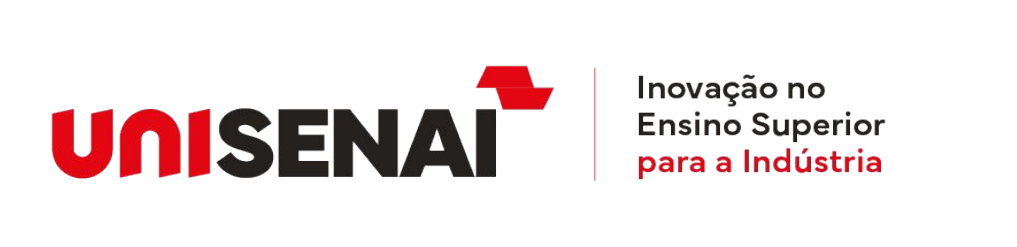

**PÓS-GRADUAÇÃO**  
Data Science & Big Data Aplicados na Indústria

---

# Aula 02 — Pandas, análise exploratória e dados industriais

**Matéria: Data Science e Big Data**

| Identificação | Informações |
| :--- | :--- |
| **Aluno** | Carlos Pereira |
| **Disciplina** | Data Science e Big Data |
| **Professor** | Daniel Vieira |


> Aula guiada baseada no PDF da aula02: fundamentos, exemplos, exercícios resolvidos e projeto de manutenção.


# Aula 02 completa: Data Science e Big Data na indústria
## Da pergunta de negócio à análise com Pandas

Este caderno segue o modelo da aula03: explicação, código comentado, resultado e interpretação.
**Aluno: Carlos Pereira | Professor: Daniel Vieira.** Execute as células na ordem em Python 3.
As saídas da execução local estão salvas; a seção de Spark informa separadamente sua disponibilidade.

| Parte | Conteúdo | Páginas do PDF |
|---|---|---|
| Fundamentos | Etapas, problemas, ferramentas, Series e DataFrame | 2 a 18 |
| Exemplo 1 | Produção, defeitos e temperatura | 19 a 34 |
| Exemplo 2 | Produção e qualidade por turno | 35 a 48 e 51 |
| Exercícios resolvidos | Máquinas, viagens e vendas | 49 a 56 |
| Projeto S&M Industry | Cinco etapas, análises e recomendações | 57 a 80 |

**Arquivos:** mantenha a pasta `dados` junto ao notebook. Os quatro CSVs foram obtidos dos links do próprio PDF.
Os exemplos pequenos foram transcritos das tabelas dos slides. Não há dados simulados apresentados como originais.
No Colab, envie os CSVs para uma pasta `dados` ou diretamente para `/content`: o carregador aceita as duas opções.

**Como estudar:** primeiro execute; depois explique cada resultado; por fim altere um filtro ou gráfico e compare.
As implementações do projeto são complementos autorais, pois o PDF apresenta seu roteiro, não uma solução pronta.

## 1. Antes do código: qual pergunta os dados devem responder? · páginas 2 a 7

Um projeto começa com uma decisão concreta: investigar defeitos, comparar turnos ou apoiar manutenção.
A preparação verifica o que foi medido, em qual período e com quais unidades. A análise ou o algoritmo
produz evidências; o teste e a interpretação verificam se elas ajudam a responder à pergunta inicial.

| Etapa | Aplicação nesta aula |
|---|---|
| Definição do problema | A temperatura se associa ao aumento de defeitos? |
| Preparação | Construir tabelas, ler CSVs e verificar qualidade |
| Escolha do método | Filtrar, agrupar, calcular correlações; no projeto, treinar modelos |
| Teste | Conferir cálculos e reservar dados para avaliar previsões |
| Visualização e interpretação | Relacionar resultados com a decisão industrial |

Os slides ilustram **associação** (tempo de empresa e salário), **regressão** (preço de imóvel),
**classificação** (vinho, defeito ou eficiência), **comparação** (investimentos) e **agrupamento**
(perfis de máquinas). A pergunta determina o método. Correlação sozinha não demonstra causa.

Python é a linguagem; Pandas manipula tabelas; Jupyter/Colab organiza texto e código; Matplotlib desenha gráficos.
Spark aparece quando o processamento distribuído se justifica pelo volume e pela infraestrutura.

## 2. Ambiente e primeiros objetos · páginas 8 a 12

Uma **Series** representa uma coluna com índice. Um **DataFrame** reúne colunas alinhadas pelo índice.
Cada linha deve representar uma observação coerente, como uma medição, máquina ou turno.
O índice padrão começa em zero e não é automaticamente um identificador industrial.

A instalação abaixo é opcional. Se aparecer `NameError`, execute as células anteriores; se aparecer
`ModuleNotFoundError`, instale a biblioteca no kernel em uso e reinicie a execução.

In [29]:
# Descomente somente se necessário no Jupyter ou Colab:
# %pip install pandas numpy matplotlib scikit-learn
# Opcional para a etapa 5 do projeto: %pip install pyspark

In [30]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})

def ler_base(nome):
    # Aceita a estrutura entregue e o upload direto no Colab.
    for caminho in [Path('dados') / nome, Path(nome)]:
        if caminho.is_file():
            return pd.read_csv(caminho, encoding='utf-8-sig')
    raise FileNotFoundError(f'Envie {nome} para a pasta dados ou para a pasta atual.')

serie = pd.Series([70, 82, 73], name='temperatura', index=['registro A', 'registro B', 'registro C'])
display(serie)
print('Pandas:', pd.__version__)

registro A    70
registro B    82
registro C    73
Name: temperatura, dtype: int64

Pandas: 2.3.1


## 3. Exemplo 1: temperatura e defeitos · páginas 19 e 20

Reproduzimos os cinco registros do PDF. `dados` é um dicionário: as chaves viram colunas e as listas
fornecem os valores. A mesma posição em cada lista pertence à mesma observação.
O produto se repete porque há mais de um registro por produto.

**Pergunta:** os maiores valores de temperatura aparecem junto aos maiores números de defeitos?
Não conhecemos o período, a calibração dos sensores nem a seleção desses cinco registros.

In [31]:
dados = {
    'produto': ['Motor A', 'Motor B', 'Motor A', 'Motor C', 'Motor B'],
    'producao': [100, 120, 110, 90, 130],
    'defeitos': [5, 12, 6, 3, 15],
    'temperatura': [70, 82, 73, 68, 85]
}
df = pd.DataFrame(dados)
display(df)

,produto,producao,defeitos,temperatura
0,Motor A,100,5,70
1,Motor B,120,12,82
2,Motor A,110,6,73
3,Motor C,90,3,68
4,Motor B,130,15,85


### 3.1. Visualizar e conferir a tabela · páginas 21 e 22

`head()` mostra cinco linhas por padrão; `info()` informa tipos e valores não nulos;
`describe()` resume colunas numéricas. `shape` retorna linhas e colunas.
Uma média só faz sentido depois de conferir o que cada linha representa.

In [32]:
display(df.head())
df.info()
print('Linhas e colunas:', df.shape)
print('Colunas:', df.columns.tolist())
display(df.describe())

,produto,producao,defeitos,temperatura
0,Motor A,100,5,70
1,Motor B,120,12,82
2,Motor A,110,6,73
3,Motor C,90,3,68
4,Motor B,130,15,85


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   produto      5 non-null      object
 1   producao     5 non-null      int64 
 2   defeitos     5 non-null      int64 
 3   temperatura  5 non-null      int64 
dtypes: int64(3), object(1)
memory usage: 292.0+ bytes
Linhas e colunas: (5, 4)
Colunas: ['produto', 'producao', 'defeitos', 'temperatura']


,producao,defeitos,temperatura
count,5.000000,5.000000,5.000000
mean,110.000000,8.200000,75.600000
std,15.811388,5.069517,7.503333
min,90.000000,3.000000,68.000000
25%,100.000000,5.000000,70.000000
50%,110.000000,6.000000,73.000000
75%,120.000000,12.000000,82.000000
max,130.000000,15.000000,85.000000


### 3.2. Selecionar colunas e filtrar linhas · páginas 23 a 26

`df['temperatura']` retorna uma Series. Usar uma lista dentro dos colchetes retorna um DataFrame.
Uma condição gera uma máscara de verdadeiro/falso. Para combinar condições use `&` e parênteses.
`loc` seleciona por rótulo ou condição; `iloc` seleciona por posição.

In [33]:
display(df['temperatura'])
display(df[['produto', 'temperatura']])
display(df[df['temperatura'] > 75])
display(df[(df['temperatura'] > 75) & (df['defeitos'] > 10)])
# Complementos que mostram outras formas de selecionar os mesmos dados:
display(df.loc[df['temperatura'] > 75, ['produto', 'defeitos']])
display(df.iloc[:2, :3])
display(df.query('temperatura > 75'))

0    70
1    82
2    73
3    68
4    85
Name: temperatura, dtype: int64

,produto,temperatura
0,Motor A,70
1,Motor B,82
2,Motor A,73
3,Motor C,68
4,Motor B,85


,produto,producao,defeitos,temperatura
1,Motor B,120,12,82
4,Motor B,130,15,85


,produto,producao,defeitos,temperatura
1,Motor B,120,12,82
4,Motor B,130,15,85


,produto,defeitos
1,Motor B,12
4,Motor B,15


,produto,producao,defeitos
0,Motor A,100,5
1,Motor B,120,12


,produto,producao,defeitos,temperatura
1,Motor B,120,12,82
4,Motor B,130,15,85


### 3.3. Média, extremos e ordenação · páginas 27 a 29

`mean`, `min` e `max` resumem os valores. `sort_values` reorganiza linhas completas;
`ascending=False` coloca os maiores primeiro. O resultado só altera a variável original se for atribuído.

In [34]:
print(f"Temperatura média: {df['temperatura'].mean():.1f}")
print(f"Produção média: {df['producao'].mean():.1f} peças")
print('Temperatura mínima:', df['temperatura'].min())
print('Temperatura máxima:', df['temperatura'].max())
display(df.sort_values(by='temperatura', ascending=False))

Temperatura média: 75.6
Produção média: 110.0 peças
Temperatura mínima: 68
Temperatura máxima: 85


,produto,producao,defeitos,temperatura
4,Motor B,130,15,85
1,Motor B,120,12,82
2,Motor A,110,6,73
0,Motor A,100,5,70
3,Motor C,90,3,68


### 3.4. Agrupar por produto · páginas 30 a 32

`groupby` separa os registros por produto e a agregação resume cada grupo. `mean` calcula a média
por registro, enquanto `sum` calcula o total. `agg` permite combinar operações em uma tabela.

In [35]:
display(df.groupby('produto')['producao'].mean())
display(df.groupby('produto')['defeitos'].mean())
display(df.groupby('produto').agg({'producao': 'mean', 'defeitos': 'sum', 'temperatura': 'mean'}))
display(df['produto'].value_counts())

produto
Motor A    105.0
Motor B    125.0
Motor C     90.0
Name: producao, dtype: float64

produto
Motor A     5.5
Motor B    13.5
Motor C     3.0
Name: defeitos, dtype: float64

,producao,defeitos,temperatura
produto,,,
Motor A,105.0,11,71.5
Motor B,125.0,27,83.5
Motor C,90.0,3,68.0


produto
Motor A    2
Motor B    2
Motor C    1
Name: count, dtype: int64

### 3.5. Criar taxa de defeitos e calcular correlação · páginas 33 e 34

**Taxa de defeitos (%) = defeitos / produção × 100.** A taxa permite comparar volumes diferentes.
O denominador precisa ser positivo. A correlação de Pearson varia entre -1 e 1 e mede associação linear.
Selecionamos apenas colunas numéricas para evitar tentar correlacionar nomes de produtos.

,produto,producao,defeitos,temperatura,taxa_defeitos
0,Motor A,100,5,70,5.000000
1,Motor B,120,12,82,10.000000
2,Motor A,110,6,73,5.454545
3,Motor C,90,3,68,3.333333
4,Motor B,130,15,85,11.538462


,producao,defeitos,temperatura
producao,1.000000,0.966863,0.969334
defeitos,0.966863,1.000000,0.995051
temperatura,0.969334,0.995051,1.000000


Correlação entre temperatura e número de defeitos: 0.9951


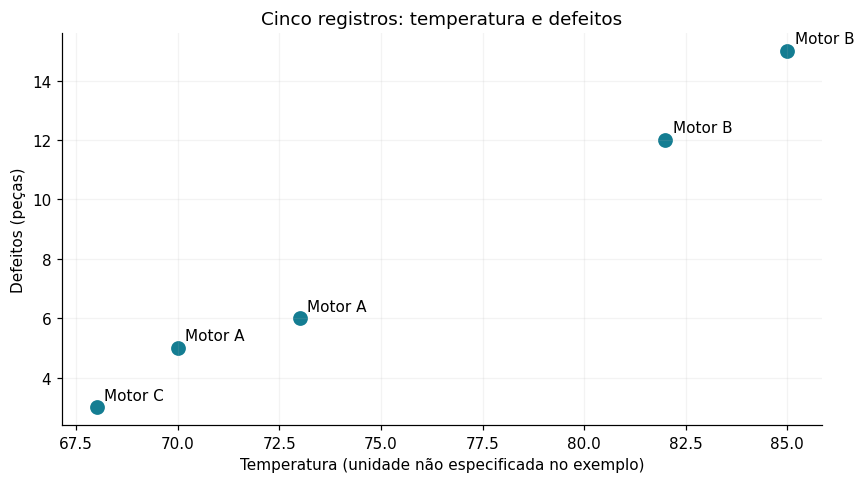

In [36]:
df['taxa_defeitos'] = df['defeitos'].div(df['producao'].where(df['producao'] > 0)) * 100
display(df)
display(df[['producao', 'defeitos', 'temperatura']].corr())
r_temperatura = df['temperatura'].corr(df['defeitos'])
print(f'Correlação entre temperatura e número de defeitos: {r_temperatura:.4f}')
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(df['temperatura'], df['defeitos'], s=75, color='#147d92')
for _, linha in df.iterrows():
    ax.annotate(linha['produto'], (linha['temperatura'], linha['defeitos']), xytext=(5, 5), textcoords='offset points')
ax.set(xlabel='Temperatura (unidade não especificada no exemplo)', ylabel='Defeitos (peças)',
       title='Cinco registros: temperatura e defeitos')
ax.grid(alpha=.15)
plt.tight_layout()
plt.show()

**Interpretação:** a associação linear é positiva e forte nesta amostra, mas são apenas cinco registros.
Produto e volume também mudam entre linhas. A evidência não permite concluir que aquecer a máquina causa defeitos.
Seria necessário acompanhar mais registros comparáveis e investigar processo, produto e medição.

## 4. Caixa de ferramentas do Pandas · páginas 13 a 18

Os slides também listam limpeza, junção e exportação. O exemplo abaixo é um **complemento didático**
com uma cópia alterada, sem substituir a tabela original.

| Operação | Comando | Uso |
|---|---|---|
| Leitura | `read_csv`, `read_excel`, `read_parquet` | Depende do formato; Excel e Parquet podem exigir bibliotecas adicionais |
| Inspeção | `head`, `tail`, `shape`, `columns`, `info`, `describe` | Conhecer estrutura e tipos |
| Resumo | `sum`, `mean`, `median`, `std`, `min`, `max` | Resumir medidas |
| Seleção | `loc`, `iloc`, `query` | Escolher linhas e colunas |
| Limpeza | `isnull`, `dropna`, `fillna`, `drop`, `rename`, `astype` | Tratar ausências, nomes e tipos |
| Integração | `concat`, `merge` | Empilhar registros ou juntar por chave |
| Exportação | `to_csv`, `to_excel` | Salvar resultados |

O PDF cita Kaggle, dados.gov.br e Brasil.IO como fontes. Antes de usar uma base, confira procedência,
licença, dicionário, período e adequação à pergunta.

In [37]:
amostra = df.copy()
amostra.loc[0, 'temperatura'] = np.nan
display(amostra.isnull().sum())
print('Linhas completas:', len(amostra.dropna()))
amostra['temperatura'] = amostra['temperatura'].fillna(amostra['temperatura'].median())
display(amostra.rename(columns={'producao': 'pecas'}).drop(columns='taxa_defeitos').astype({'defeitos': 'float64'}).tail(2))
print('Mediana e desvio padrão amostral:', df['producao'].median(), df['producao'].std())
display(pd.concat([df.iloc[:2], df.iloc[2:]], ignore_index=True))
cadastro = pd.DataFrame({'produto': ['Motor A', 'Motor B', 'Motor C'], 'familia': ['A', 'B', 'C']})
display(df.merge(cadastro, on='produto', how='left', validate='many_to_one'))
# Exportação em memória para demonstrar sem criar arquivos extras:
csv_em_memoria = df.to_csv(index=False)
print(csv_em_memoria.splitlines()[0])

produto          0
producao         0
defeitos         0
temperatura      1
taxa_defeitos    0
dtype: int64

Linhas completas: 4


,produto,pecas,defeitos,temperatura
3,Motor C,90,3.0,68.0
4,Motor B,130,15.0,85.0


Mediana e desvio padrão amostral: 110.0 15.811388300841896


,produto,producao,defeitos,temperatura,taxa_defeitos
0,Motor A,100,5,70,5.000000
1,Motor B,120,12,82,10.000000
2,Motor A,110,6,73,5.454545
3,Motor C,90,3,68,3.333333
4,Motor B,130,15,85,11.538462


,produto,producao,defeitos,temperatura,taxa_defeitos,familia
0,Motor A,100,5,70,5.000000,A
1,Motor B,120,12,82,10.000000,B
2,Motor A,110,6,73,5.454545,A
3,Motor C,90,3,68,3.333333,C
4,Motor B,130,15,85,11.538462,B


produto,producao,defeitos,temperatura,taxa_defeitos


## 5. Exemplo 2: desempenho e qualidade por turno · páginas 35 a 48

Uma indústria acompanha peças produzidas, aprovadas e defeituosas por turno. Lemos a base original
vinculada na página 35. Cada linha é um registro do turno, não uma máquina individual.
Primeiro conferimos se aprovadas + defeituosas = produzidas.

In [38]:
producao = ler_base('producao.csv')
producao['data'] = pd.to_datetime(producao['data'], errors='raise')
display(producao.head())
producao.info()
assert producao[['pecas_produzidas', 'pecas_defeituosas', 'pecas_aprovadas']].notna().all().all()
assert (producao['pecas_produzidas'] > 0).all()
assert (producao['pecas_aprovadas'] + producao['pecas_defeituosas']).equals(producao['pecas_produzidas'])
print('Período:', producao['data'].min().date(), 'a', producao['data'].max().date())
print('Duplicatas exatas:', producao.duplicated().sum())

,data,turno,produto,pecas_produzidas,pecas_defeituosas,pecas_aprovadas
0,2026-01-01,Manhã,Peça metálica A,281,13,268
1,2026-01-01,Tarde,Peça metálica A,240,4,236
2,2026-01-01,Noite,Peça metálica A,297,10,287
3,2026-01-02,Manhã,Peça metálica A,335,16,319
4,2026-01-02,Tarde,Peça metálica A,296,9,287


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   data               100 non-null    datetime64[ns]
 1   turno              100 non-null    object        
 2   produto            100 non-null    object        
 3   pecas_produzidas   100 non-null    int64         
 4   pecas_defeituosas  100 non-null    int64         
 5   pecas_aprovadas    100 non-null    int64         
dtypes: datetime64[ns](1), int64(3), object(2)
memory usage: 4.8+ KB
Período: 2026-01-01 a 2026-02-03
Duplicatas exatas: 0


### 5.1. Respostas a, b e c · páginas 36 a 40

Somamos as peças para responder ao total e agrupamos por turno para comparar produção e média por registro.
`idxmax()` retorna o rótulo do maior valor. As médias usam o número de registros de cada turno como denominador.

In [39]:
total_producao = producao['pecas_produzidas'].sum()
producao_turno = producao.groupby('turno')['pecas_produzidas'].sum()
media_turno = producao.groupby('turno')['pecas_produzidas'].mean()
print(f'a) Total produzido: {total_producao:,} peças')
print('b) Maior produção total:', producao_turno.idxmax())
print('c) Produção média por registro:')
display(media_turno.round(2))

a) Total produzido: 29,479 peças
b) Maior produção total: Manhã
c) Produção média por registro:


turno
Manhã    316.97
Noite    265.61
Tarde    301.12
Name: pecas_produzidas, dtype: float64

### 5.2. Resposta d: qualidade proporcional ao volume · páginas 41 a 43

Calculamos **soma dos defeitos / soma da produção × 100** por turno. Fazer a média simples das taxas
por linha daria o mesmo peso a registros com volumes diferentes. Também mostramos a quantidade de registros.

In [40]:
resumo = producao.groupby('turno').agg(
    registros=('pecas_produzidas', 'size'),
    pecas_produzidas=('pecas_produzidas', 'sum'),
    pecas_defeituosas=('pecas_defeituosas', 'sum'),
    media_producao=('pecas_produzidas', 'mean'))
resumo['taxa_defeitos'] = resumo['pecas_defeituosas'] / resumo['pecas_produzidas'] * 100
display(resumo.round(3))
print('d) Maior percentual de defeitos:', resumo['taxa_defeitos'].idxmax())
print(f"Percentual: {resumo['taxa_defeitos'].max():.3f}%")

,registros,pecas_produzidas,pecas_defeituosas,media_producao,taxa_defeitos
turno,,,,,
Manhã,34,10777,358,316.971,3.322
Noite,33,8765,277,265.606,3.160
Tarde,33,9937,306,301.121,3.079


d) Maior percentual de defeitos: Manhã
Percentual: 3.322%


### 5.3. Visualizar os resultados · páginas 44 a 48

`fig` representa a figura inteira e `ax` a região onde os dados são desenhados. `figsize` define
largura e altura em polegadas. Corrigimos o slide definindo `resumo` antes de utilizá-lo nos gráficos.
Mantemos os dois gráficos separados porque peças e porcentagens têm unidades diferentes.

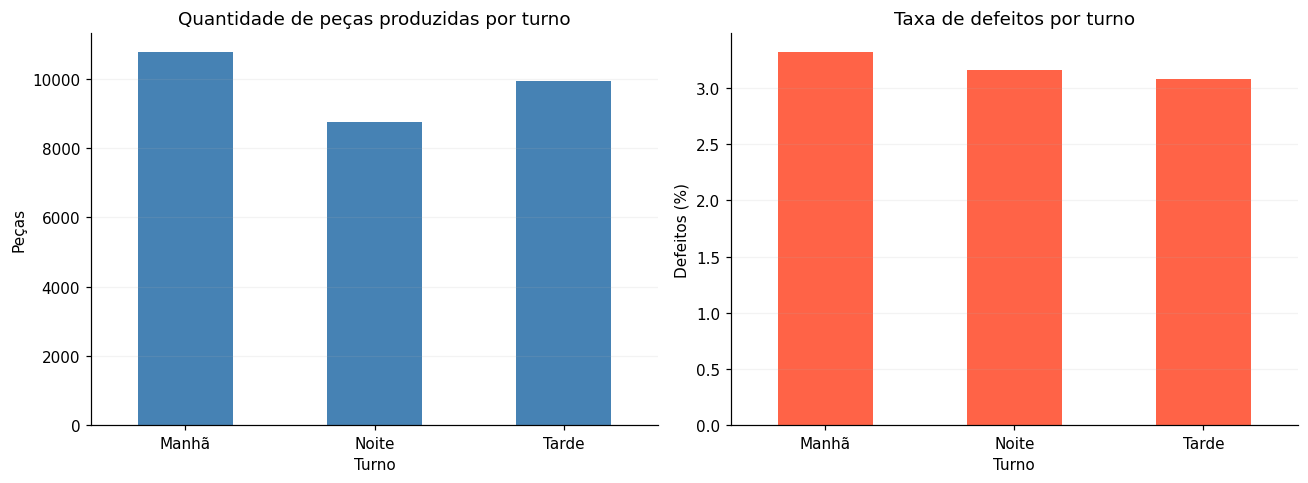

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
resumo['pecas_produzidas'].plot.bar(ax=axes[0], color='steelblue', rot=0)
axes[0].set(title='Quantidade de peças produzidas por turno', xlabel='Turno', ylabel='Peças')
resumo['taxa_defeitos'].plot.bar(ax=axes[1], color='tomato', rot=0)
axes[1].set(title='Taxa de defeitos por turno', xlabel='Turno', ylabel='Defeitos (%)')
for ax in axes:
    ax.grid(axis='y', alpha=.15)
plt.tight_layout()
plt.show()

**Leitura:** o turno da manhã lidera a produção total e também tem a maior taxa de defeitos nesta base.
O turno da tarde apresenta a menor taxa. Isso orienta uma investigação, mas não comprova que o turno cause
o resultado: produto, equipe, equipamento e condições de operação podem diferir.

### 5.4. Questão da página 51: produção e peças defeituosas

Essa pergunta necessita da base de produção, que possui as duas medidas. A tabela de máquinas do exercício 1
não contém defeitos. Calculamos aqui a correlação e mostramos o gráfico para resolver a ambiguidade do material.

Correlação entre produção e quantidade de peças defeituosas: 0.3697


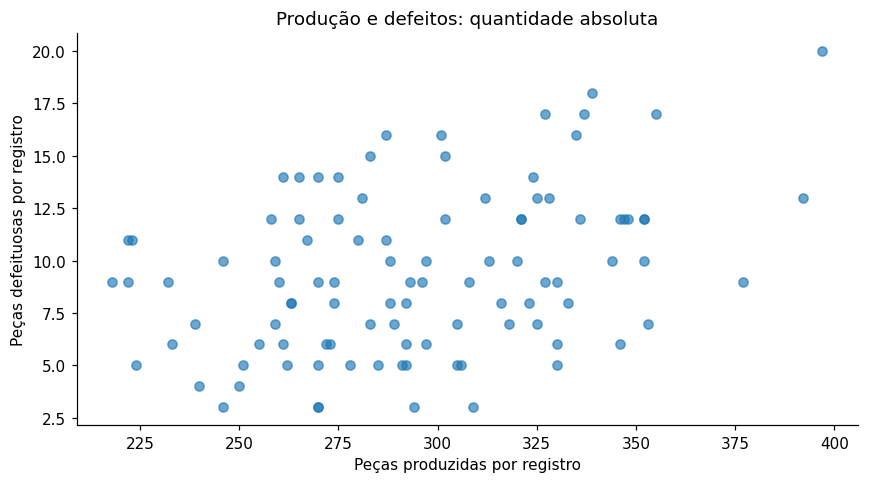

Maior volume pode aumentar o número absoluto de defeitos mesmo com taxa semelhante.


In [42]:
r_producao = producao['pecas_produzidas'].corr(producao['pecas_defeituosas'])
print(f'Correlação entre produção e quantidade de peças defeituosas: {r_producao:.4f}')
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(producao['pecas_produzidas'], producao['pecas_defeituosas'], alpha=.65)
ax.set(xlabel='Peças produzidas por registro', ylabel='Peças defeituosas por registro',
       title='Produção e defeitos: quantidade absoluta')
plt.tight_layout()
plt.show()
print('Maior volume pode aumentar o número absoluto de defeitos mesmo com taxa semelhante.')

## 6. Exercício 1 resolvido: produção e energia · páginas 49 e 50

Os valores a seguir são os da tabela do PDF. Cada observação representa uma máquina em um turno.
**Eficiência = produção / energia**, em peças por kWh. Maior produção e melhor eficiência são critérios diferentes.

In [43]:
maquinas = pd.DataFrame({
    'maquina': ['Máquina A', 'Máquina B', 'Máquina C', 'Máquina D', 'Máquina E'],
    'producao': [1250, 1380, 1190, 1450, 1320],
    'energia_kwh': [420, 465, 390, 510, 405]
})
display(maquinas)
print('a) Maior produção:', maquinas.loc[maquinas['producao'].idxmax(), 'maquina'])
print('b) Menor consumo:', maquinas.loc[maquinas['energia_kwh'].idxmin(), 'maquina'])
print(f"c) Produção média: {maquinas['producao'].mean():.1f} peças/turno")
print(f"d) Energia média: {maquinas['energia_kwh'].mean():.1f} kWh/turno")
print('e) Ordem decrescente de produção:')
display(maquinas.sort_values('producao', ascending=False))
maquinas['eficiencia'] = maquinas['producao'] / maquinas['energia_kwh']
print('f) Eficiência em peças/kWh:')
display(maquinas.round(4))
melhor_maquina = maquinas.loc[maquinas['eficiencia'].idxmax()]
print(f"g) Melhor relação: {melhor_maquina['maquina']} ({melhor_maquina['eficiencia']:.4f} peças/kWh)")

,maquina,producao,energia_kwh
0,Máquina A,1250,420
1,Máquina B,1380,465
2,Máquina C,1190,390
3,Máquina D,1450,510
4,Máquina E,1320,405


a) Maior produção: Máquina D
b) Menor consumo: Máquina C
c) Produção média: 1318.0 peças/turno
d) Energia média: 438.0 kWh/turno
e) Ordem decrescente de produção:


,maquina,producao,energia_kwh
3,Máquina D,1450,510
1,Máquina B,1380,465
4,Máquina E,1320,405
0,Máquina A,1250,420
2,Máquina C,1190,390


f) Eficiência em peças/kWh:


,maquina,producao,energia_kwh,eficiencia
0,Máquina A,1250,420,2.9762
1,Máquina B,1380,465,2.9677
2,Máquina C,1190,390,3.0513
3,Máquina D,1450,510,2.8431
4,Máquina E,1320,405,3.2593


g) Melhor relação: Máquina E (3.2593 peças/kWh)


**Respostas:** D produz mais (1.450 peças); C consome menos (390 kWh); a produção média é 1.318 peças
e o consumo médio é 438 kWh. A ordem de produção é D, B, E, A, C. E tem a melhor relação,
aproximadamente 3,2593 peças/kWh. A comparação pressupõe peças e condições operacionais compatíveis.

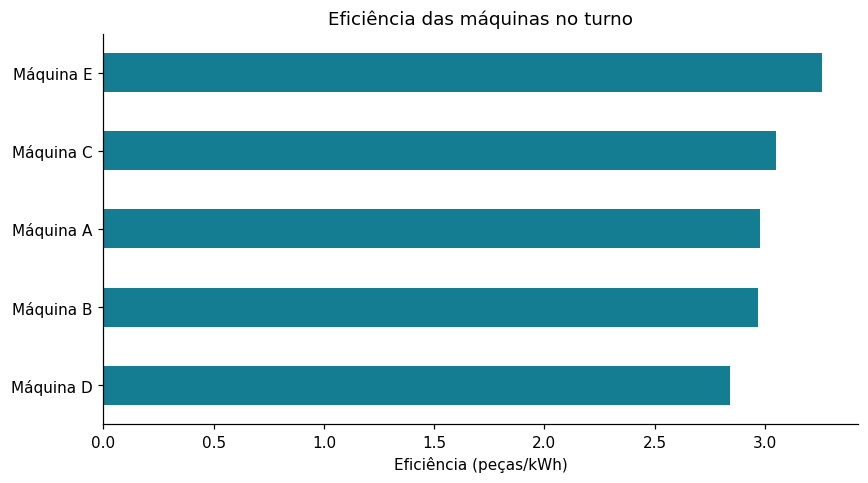

In [58]:
fig, ax = plt.subplots(figsize=(8, 4.5))
maquinas.set_index('maquina')['eficiencia'].sort_values().plot.barh(ax=ax, color='#147d92')
ax.set(xlabel='Eficiência (peças/kWh)', ylabel='', title='Eficiência das máquinas no turno')
plt.tight_layout()
plt.show()

## 7. Exercício 2 resolvido: transporte e logística · páginas 52 e 53

Cada registro contém data, dia da semana, viagens e distância. Convertemos a data antes de agrupar.
Agregamos por dia antes de buscar o máximo ou calcular a média diária; isso também funciona se houver
várias linhas na mesma data. Os meses são identificados por ano e mês para não misturar anos.

In [45]:
viagens = ler_base('base_p52.csv')
viagens['data'] = pd.to_datetime(viagens['data'], errors='raise')
display(viagens.head())
diario = viagens.groupby('data')[['quantidade_viagens', 'distancia_total_km']].sum(min_count=1)
mensal_viagens = diario.groupby(diario.index.to_period('M'))['quantidade_viagens'].sum()
print('a) Total de viagens:', diario['quantidade_viagens'].sum())
print('b) Dia(s) de maior quantidade:')
display(diario.loc[diario['quantidade_viagens'].eq(diario['quantidade_viagens'].max())])
print(f"c) Média por dia observado: {diario['quantidade_viagens'].mean():.2f} viagens")
print('d) Mês(es) de maior total:')
display(mensal_viagens[mensal_viagens.eq(mensal_viagens.max())])
r_viagens = diario['quantidade_viagens'].corr(diario['distancia_total_km'])
print(f'e) Correlação de Pearson entre viagens e distância: {r_viagens:.4f}')
print('Dias observados:', len(diario), '| Duplicatas exatas:', viagens.duplicated().sum())

,data,dia_semana,quantidade_viagens,distancia_total_km
0,2026-01-01,Quinta,45,824.0
1,2026-01-02,Sexta,32,632.7
2,2026-01-03,Sábado,21,254.8
3,2026-01-04,Domingo,31,616.9
4,2026-01-05,Segunda,37,698.9


a) Total de viagens: 2893
b) Dia(s) de maior quantidade:


,quantidade_viagens,distancia_total_km
data,,
2026-02-26,48,969.1
2026-03-18,48,1065.5


c) Média por dia observado: 28.93 viagens
d) Mês(es) de maior total:


data
2026-01    901
Freq: M, Name: quantidade_viagens, dtype: int64

e) Correlação de Pearson entre viagens e distância: 0.8694
Dias observados: 100 | Duplicatas exatas: 0


**Respostas e interpretação desta execução:** foram realizadas **2.893 viagens**. Os dias **26/02/2026 e 18/03/2026** empataram no máximo, com **48 viagens** cada. A média foi **28,93 viagens por dia observado**. Janeiro de 2026 teve o maior total, **901 viagens**. A correlação com distância foi **0,8694**, uma associação linear positiva forte nesta amostra. Isso não demonstra causalidade. A comparação mensal deve considerar os dias cobertos, sobretudo o último mês parcial.

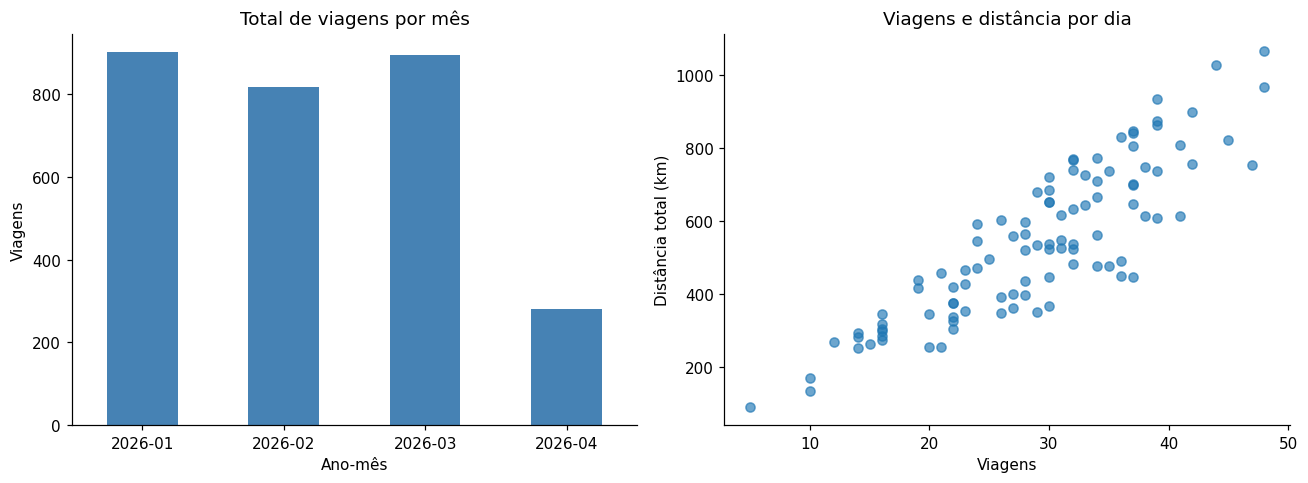

A correlação descreve associação linear; a distância média por viagem também varia.
Meses incompletos não devem ser comparados como se tivessem igual exposição.


data
2026-01    31
2026-02    28
2026-03    31
2026-04    10
Freq: M, Name: dias_observados, dtype: int64

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
mensal_viagens.plot.bar(ax=axes[0], color='steelblue', rot=0)
axes[0].set(title='Total de viagens por mês', xlabel='Ano-mês', ylabel='Viagens')
axes[1].scatter(diario['quantidade_viagens'], diario['distancia_total_km'], alpha=.65)
axes[1].set(title='Viagens e distância por dia', xlabel='Viagens', ylabel='Distância total (km)')
plt.tight_layout()
plt.show()
print('A correlação descreve associação linear; a distância média por viagem também varia.')
print('Meses incompletos não devem ser comparados como se tivessem igual exposição.')
display(diario.groupby(diario.index.to_period('M')).size().rename('dias_observados'))

## 8. Exercício 3 resolvido: vendas do Produto A · páginas 54 e 55

A base contém registros mensais. Selecionamos o Produto A, interpretamos `mes` como data e somamos
unidades e faturamento. Mantemos ano e mês juntos no máximo mensal. O preço está em reais nominais;
a associação entre preço e quantidade não isola inflação, sazonalidade ou passagem do tempo.

**Observação editorial:** as imagens de prévia das bases nas páginas 52 e 54 estão trocadas.
Os links correspondem aos enunciados: página 52 fornece viagens e página 54 fornece vendas.

In [47]:
vendas = ler_base('base_p54.csv')
vendas['mes'] = pd.to_datetime(vendas['mes'], format='%Y-%m', errors='raise')
vendas_a = vendas.loc[vendas['produto'].eq('Produto A')].copy()
display(vendas_a.head())
faturamento_mensal = vendas_a.groupby('mes')['faturamento_rs'].sum()
unidades_ano = vendas_a.groupby(vendas_a['mes'].dt.year)['unidades_vendidas'].sum()
print('a) Total de unidades:', vendas_a['unidades_vendidas'].sum())
print('b) Mês(es) com maior faturamento:')
display(faturamento_mensal[faturamento_mensal.eq(faturamento_mensal.max())])
print(f"c) Faturamento total: R$ {vendas_a['faturamento_rs'].sum():,.2f}")
print('d) Ano(s) com mais unidades:')
display(unidades_ano[unidades_ano.eq(unidades_ano.max())])
r_vendas = vendas_a['preco_unitario_rs'].corr(vendas_a['unidades_vendidas'])
print(f'e) Correlação entre preço e unidades vendidas: {r_vendas:.4f}')
print('Faturamento confere com quantidade × preço?', np.allclose(
    vendas_a['unidades_vendidas'] * vendas_a['preco_unitario_rs'], vendas_a['faturamento_rs'], atol=.011))

,mes,produto,unidades_vendidas,preco_unitario_rs,faturamento_rs
0,2018-01-01,Produto A,195,39.90,7780.50
1,2018-02-01,Produto A,142,40.13,5698.46
2,2018-03-01,Produto A,186,40.36,7506.96
3,2018-04-01,Produto A,188,40.59,7630.92
4,2018-05-01,Produto A,180,40.82,7347.60


a) Total de unidades: 24499
b) Mês(es) com maior faturamento:


mes
2025-11-01    22516.32
Name: faturamento_rs, dtype: float64

c) Faturamento total: R$ 1,281,779.17
d) Ano(s) com mais unidades:


mes
2025    3511
Name: unidades_vendidas, dtype: int64

e) Correlação entre preço e unidades vendidas: 0.7713
Faturamento confere com quantidade × preço? True


**Respostas e interpretação desta execução:** foram vendidas **24.499 unidades** do Produto A. **Novembro de 2025** apresentou o maior faturamento mensal, **R$ 22.516,32**. O faturamento total foi **R$ 1.281.779,17**; **2025** liderou as unidades vendidas, com **3.511**. A correlação entre preço e unidades foi **0,7713**. Essa associação positiva não prova que aumentar preço aumente vendas: ambas as medidas podem acompanhar o tempo, a demanda e a inflação. O último ano da série está incompleto, portanto totais anuais não têm sempre a mesma exposição.

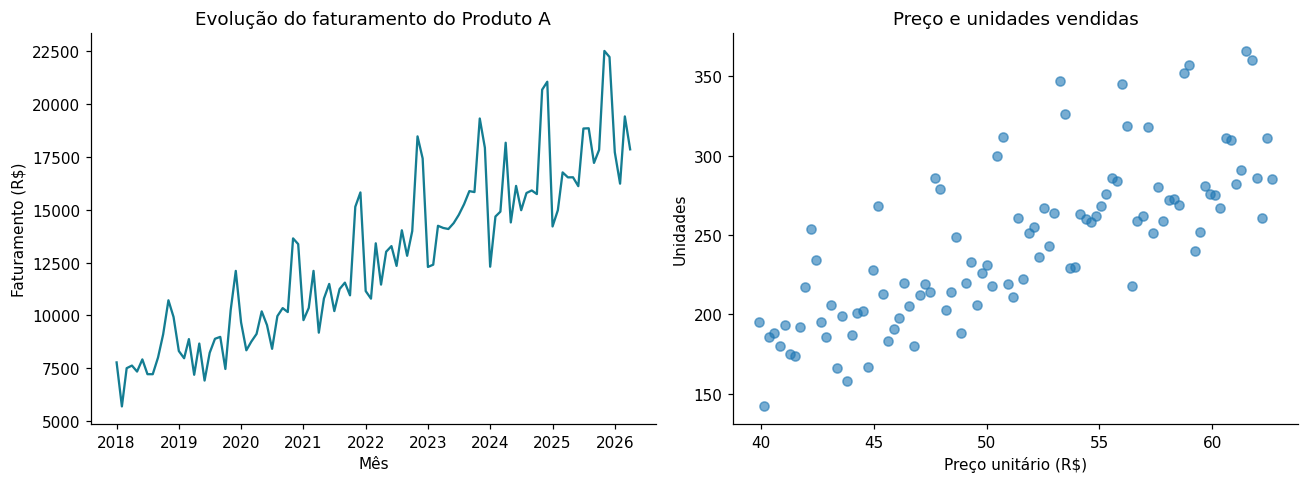

Uma correlação observada não mede, sozinha, o efeito de uma mudança de preço.


In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(vendas_a['mes'], vendas_a['faturamento_rs'], color='#147d92')
axes[0].set(title='Evolução do faturamento do Produto A', xlabel='Mês', ylabel='Faturamento (R$)')
axes[1].scatter(vendas_a['preco_unitario_rs'], vendas_a['unidades_vendidas'], alpha=.6)
axes[1].set(title='Preço e unidades vendidas', xlabel='Preço unitário (R$)', ylabel='Unidades')
plt.tight_layout()
plt.show()
print('Uma correlação observada não mede, sozinha, o efeito de uma mudança de preço.')

## 9. Projeto S&M Industry: roteiro e implementação · páginas 57 a 80

A empresa quer investigar condições associadas às falhas em cinco máquinas. O PDF propõe cinco etapas;
as células seguintes são uma **implementação autoral do roteiro com a base original da página 61**.
`falha` vale 0 (sem falha) ou 1 (com falha). Os sensores são temperatura (°C), vibração (mm/s),
pressão (bar), corrente (A) e horas de operação.

O objetivo de classificação aqui é reconhecer registros com falha usando suas condições medidas.
O material não define um horizonte de antecipação; portanto, esta análise não comprova previsão antecipada de falhas.

### 9.1. Etapa 1: compreensão e exploração · páginas 69 e 70

Respondemos quantidade de registros e atributos, tipos, distribuições, frequência de falhas e taxa por equipamento.
Primeiro apresentamos a base recebida. Depois removeremos duplicatas para as demais análises.

In [49]:
manutencao_original = ler_base('manutencao.csv')
sensores = ['temperatura_c', 'vibracao_mm_s', 'pressao_bar', 'corrente_a', 'horas_operacao']
display(manutencao_original.head())
print('Registros e atributos originais:', manutencao_original.shape)
display(pd.DataFrame({'tipo': manutencao_original.dtypes.astype(str),
                      'ausentes': manutencao_original.isna().sum()}))
display(manutencao_original[sensores].describe())
print('Falhas na base recebida:', manutencao_original['falha'].sum())
print(f"Percentual original de falha: {manutencao_original['falha'].mean():.2%}")
display(manutencao_original.groupby('maquina_id')['falha'].agg(['size', 'sum', 'mean']))

,timestamp,maquina_id,temperatura_c,vibracao_mm_s,pressao_bar,corrente_a,horas_operacao,falha
0,2026-02-05 18:00:00,M04,61.97,3.37,5.59,22.48,10154.0,0
1,2026-01-22 13:00:00,M01,60.86,2.07,6.55,23.21,2687.0,0
2,2026-01-17 05:00:00,M03,70.35,2.75,6.21,26.36,11779.0,0
3,2026-01-19 16:00:00,M02,68.22,3.55,7.23,28.03,4519.0,0
4,2026-02-07 21:00:00,M01,73.89,2.64,5.89,25.73,9899.0,0


Registros e atributos originais: (5050, 8)


,tipo,ausentes
timestamp,object,0
maquina_id,object,0
temperatura_c,float64,52
vibracao_mm_s,float64,50
pressao_bar,float64,51
corrente_a,float64,50
horas_operacao,float64,51
falha,int64,0


,temperatura_c,vibracao_mm_s,pressao_bar,corrente_a,horas_operacao
count,4998.000000,5000.000000,4999.000000,5000.000000,4999.000000
mean,67.121851,3.058512,6.501042,25.675890,6092.105421
std,12.503765,0.903735,0.649088,2.712346,3438.007256
min,41.330000,0.230000,4.250000,14.810000,102.000000
25%,61.590000,2.520000,6.070000,23.850000,3086.000000
50%,66.525000,3.030000,6.500000,25.680000,6120.000000
75%,71.390000,3.540000,6.940000,27.440000,9003.500000
max,278.840000,15.120000,9.160000,35.330000,11999.000000


Falhas na base recebida: 906
Percentual original de falha: 17.94%


,size,sum,mean
maquina_id,,,
M01,1012,175,0.172925
M02,1009,178,0.176412
M03,1007,181,0.179742
M04,1014,192,0.189349
M05,1008,180,0.178571


### 9.2. Etapa 2: preparação e mineração · páginas 71 e 72

Removemos somente duplicatas exatas e convertemos datas. Valores extremos pelo critério de 1,5 × IQR
são sinalizados, sem exclusão automática: uma condição extrema pode ser justamente um caso de falha.
As ausências dos preditores serão imputadas dentro do pipeline, usando apenas o treino.
Não imputamos o rótulo e verificamos se ele é binário.

In [50]:
manutencao = manutencao_original.drop_duplicates().copy()
manutencao['timestamp'] = pd.to_datetime(manutencao['timestamp'], errors='raise')
manutencao = manutencao.sort_values(['timestamp', 'maquina_id']).reset_index(drop=True)
assert manutencao['falha'].notna().all() and set(manutencao['falha'].unique()) == {0, 1}
print('Duplicatas exatas removidas:', len(manutencao_original) - len(manutencao))
print('Base sem duplicatas:', manutencao.shape)
print('Duplicatas de timestamp e máquina:', manutencao.duplicated(['timestamp', 'maquina_id']).sum())
q1, q3 = manutencao[sensores].quantile(.25), manutencao[sensores].quantile(.75)
iqr = q3 - q1
extremos = ((manutencao[sensores] < q1 - 1.5 * iqr) | (manutencao[sensores] > q3 + 1.5 * iqr)).sum()
display(pd.DataFrame({'ausentes': manutencao[sensores].isna().sum(), 'sinalizados_IQR': extremos}))
taxas_maquina = manutencao.groupby('maquina_id')['falha'].agg(registros='size', falhas='sum', taxa='mean')
display(taxas_maquina)
print('Maior taxa descritiva:', taxas_maquina['taxa'].idxmax())
print(f"Falhas após deduplicação: {manutencao['falha'].sum()} ({manutencao['falha'].mean():.2%})")

Duplicatas exatas removidas: 50
Base sem duplicatas: (5000, 8)
Duplicatas de timestamp e máquina: 0


,ausentes,sinalizados_IQR
temperatura_c,50,49
vibracao_mm_s,50,68
pressao_bar,50,40
corrente_a,50,37
horas_operacao,50,0


,registros,falhas,taxa
maquina_id,,,
M01,1000,175,0.175
M02,1000,178,0.178
M03,1000,181,0.181
M04,1000,189,0.189
M05,1000,180,0.180


Maior taxa descritiva: M04
Falhas após deduplicação: 903 (18.06%)


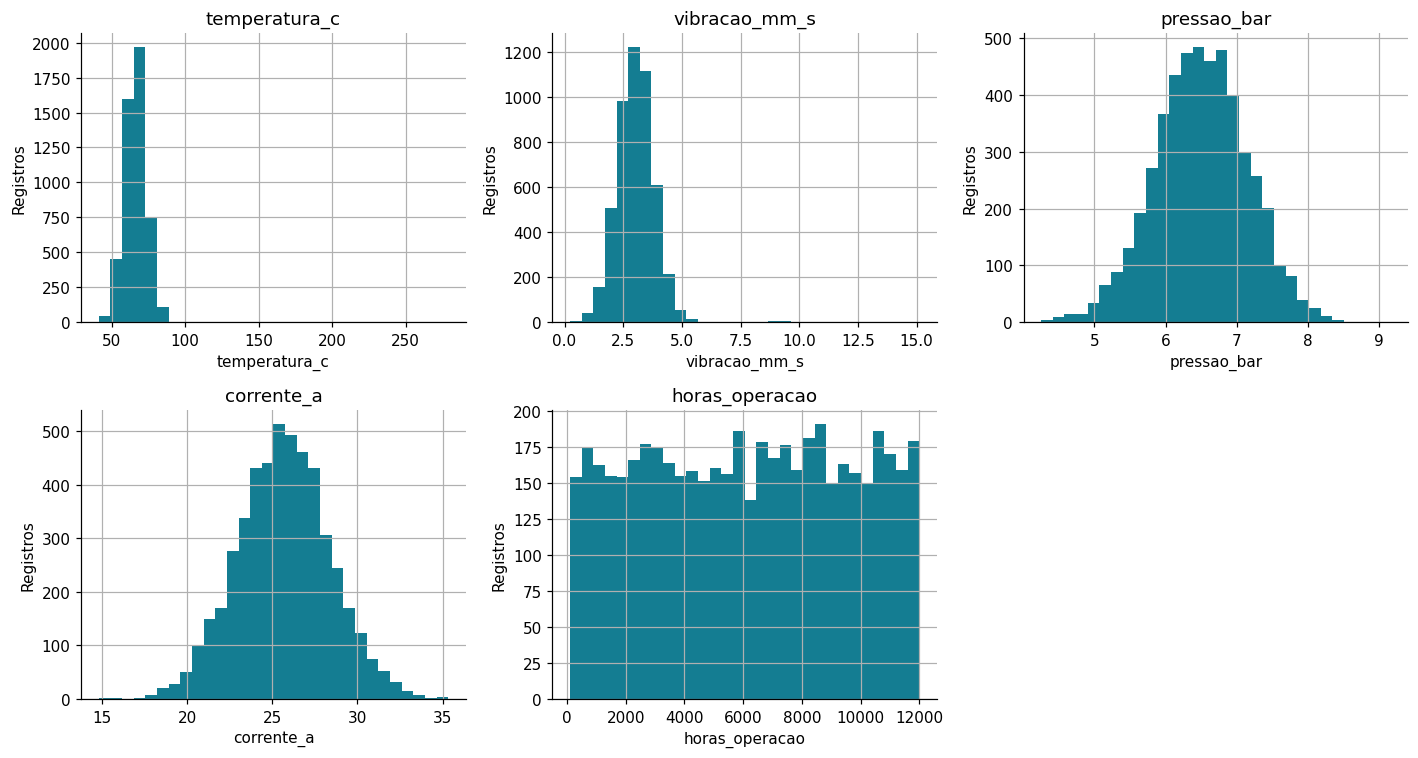

pressao_bar      -0.021649
temperatura_c     0.111714
corrente_a        0.163049
vibracao_mm_s     0.303858
horas_operacao    0.380739
Name: correlacao_Pearson_com_falha, dtype: float64

,temperatura_c,vibracao_mm_s,pressao_bar,corrente_a,horas_operacao
falha,,,,,
0,65.870,2.91,6.51,25.47,5280.5
1,69.685,3.60,6.48,26.60,9547.5


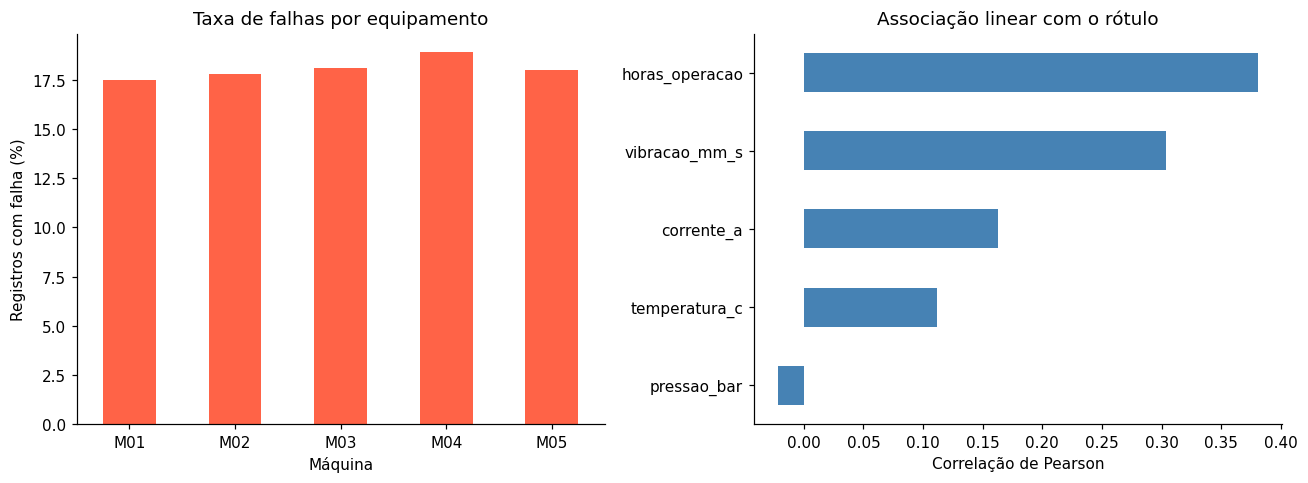

In [51]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for nome, ax in zip(sensores, axes.ravel()):
    manutencao[nome].hist(ax=ax, bins=30, color='#147d92')
    ax.set(title=nome, ylabel='Registros', xlabel=nome)
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.show()
correlacoes_falha = manutencao[sensores + ['falha']].corr()['falha'].drop('falha').sort_values()
display(correlacoes_falha.rename('correlacao_Pearson_com_falha'))
display(manutencao.groupby('falha')[sensores].median())
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
taxas_maquina['taxa'].mul(100).plot.bar(ax=axes[0], rot=0, color='tomato')
axes[0].set(title='Taxa de falhas por equipamento', xlabel='Máquina', ylabel='Registros com falha (%)')
correlacoes_falha.plot.barh(ax=axes[1], color='steelblue')
axes[1].set(title='Associação linear com o rótulo', xlabel='Correlação de Pearson')
plt.tight_layout()
plt.show()

**Como interpretar a etapa 2:** compare as medianas por classe e os sinais das correlações para temperatura,
vibração, corrente e horas de operação. Uma correlação pequena pode coexistir com relações não lineares.
Os cálculos usam pares não ausentes; não provam causalidade nem definem limites técnicos de segurança.
Uma taxa elevada por equipamento precisa ser contextualizada por condições e tempo de exposição.

### 9.3. Etapa 3: classificação supervisionada · páginas 73 e 74

Comparamos Árvore de Decisão, Random Forest e Regressão Logística. As entradas são os cinco sensores;
excluímos o identificador da máquina e o horário nesta primeira comparação para focar condições medidas.
Reservamos os 20% finais dos instantes para teste, mantendo registros do mesmo instante juntos.
Dentro do período de treino, usamos divisão temporal para escolher o modelo por F1 médio.
O teste final será usado uma única vez para o modelo escolhido e para uma referência majoritária.

Isso reduz o otimismo de escolher um modelo pelo teste. As máquinas aparecem nos dois períodos: a avaliação
representa novas medições dessas máquinas e não generalização para equipamentos inéditos. Estatísticas
exploratórias do conjunto completo não foram usadas para escolher hiperparâmetros.

In [52]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

instantes = np.sort(manutencao['timestamp'].unique())
limite = instantes[int(len(instantes) * .8)]
mascara_treino = manutencao['timestamp'] < limite
X_treino = manutencao.loc[mascara_treino, sensores]
y_treino = manutencao.loc[mascara_treino, 'falha']
X_teste = manutencao.loc[~mascara_treino, sensores]
y_teste = manutencao.loc[~mascara_treino, 'falha']
print('Treino:', len(X_treino), '| Teste:', len(X_teste), '| Corte:', limite)
print('Classes no treino:', y_treino.value_counts().to_dict())
print('Classes no teste:', y_teste.value_counts().to_dict())

estimadores = {
    'Árvore': DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=120, max_depth=8, class_weight='balanced', random_state=42, n_jobs=1),
    'Regressão Logística': LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)
}
pipelines = {nome: Pipeline([('imputacao', SimpleImputer(strategy='median')),
    ('escala', StandardScaler()), ('modelo', estimador)]) for nome, estimador in estimadores.items()}
# Dividimos instantes, depois mapeamos para posições: um instante não cruza treino e validação.
tempos_treino = manutencao.loc[mascara_treino, 'timestamp'].reset_index(drop=True)
instantes_treino = np.sort(tempos_treino.unique())
divisoes = []
for a, b in TimeSeriesSplit(n_splits=3).split(instantes_treino):
    divisoes.append((np.flatnonzero(tempos_treino.isin(instantes_treino[a])),
                     np.flatnonzero(tempos_treino.isin(instantes_treino[b]))))
validacao = []
for nome, pipeline in pipelines.items():
    scores = cross_val_score(pipeline, X_treino, y_treino, cv=divisoes, scoring='f1', error_score='raise')
    validacao.append({'modelo': nome, 'F1_medio_validacao': scores.mean(), 'desvio_F1': scores.std()})
comparacao_validacao = pd.DataFrame(validacao).sort_values('F1_medio_validacao', ascending=False)
display(comparacao_validacao)
nome_escolhido = comparacao_validacao.iloc[0]['modelo']
modelo_escolhido = clone(pipelines[nome_escolhido]).fit(X_treino, y_treino)
previsao = modelo_escolhido.predict(X_teste)
print('Modelo escolhido somente com o período de treino:', nome_escolhido)

Treino: 4000 | Teste: 1000 | Corte: 2026-02-03T08:00:00.000000000
Classes no treino: {0: 3285, 1: 715}
Classes no teste: {0: 812, 1: 188}


,modelo,F1_medio_validacao,desvio_F1
1,Random Forest,0.510485,0.015949
2,Regressão Logística,0.503243,0.012141
0,Árvore,0.475058,0.009410


Modelo escolhido somente com o período de treino: Random Forest


,modelo,acuracia,precisao,recall,F1
0,Random Forest,0.770,0.4261,0.6436,0.5127
1,Referência majoritária,0.812,0.0000,0.0000,0.0000


              precision    recall  f1-score   support

   Sem falha       0.91      0.80      0.85       812
       Falha       0.43      0.64      0.51       188

    accuracy                           0.77      1000
   macro avg       0.67      0.72      0.68      1000
weighted avg       0.82      0.77      0.79      1000



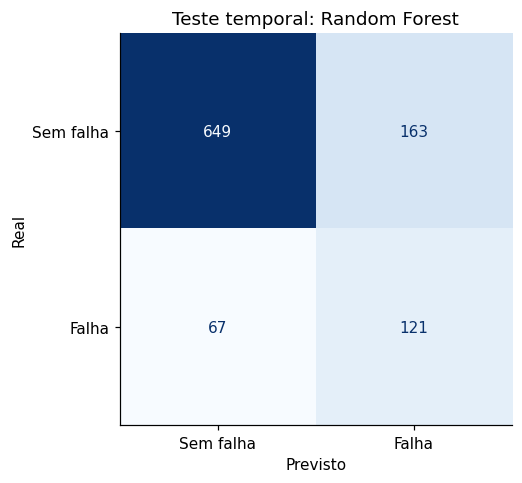

,sensor,queda_media_F1_ao_permutar,desvio
4,horas_operacao,0.165087,0.022280
1,vibracao_mm_s,0.101120,0.020846
0,temperatura_c,0.012951,0.021222
3,corrente_a,-0.001200,0.007940
2,pressao_bar,-0.012438,0.006798


In [53]:
referencia = DummyClassifier(strategy='most_frequent').fit(X_treino, y_treino)
metricas = []
for nome, previsto in [(nome_escolhido, previsao), ('Referência majoritária', referencia.predict(X_teste))]:
    metricas.append({'modelo': nome, 'acuracia': accuracy_score(y_teste, previsto),
        'precisao': precision_score(y_teste, previsto, zero_division=0),
        'recall': recall_score(y_teste, previsto, zero_division=0),
        'F1': f1_score(y_teste, previsto, zero_division=0)})
display(pd.DataFrame(metricas).round(4))
print(classification_report(y_teste, previsao, labels=[0, 1], target_names=['Sem falha', 'Falha'], zero_division=0))
fig, ax = plt.subplots(figsize=(6, 4.5))
ConfusionMatrixDisplay.from_predictions(y_teste, previsao, labels=[0, 1],
    display_labels=['Sem falha', 'Falha'], values_format='d', cmap='Blues', colorbar=False, ax=ax)
ax.set(title=f'Teste temporal: {nome_escolhido}', xlabel='Previsto', ylabel='Real')
plt.tight_layout()
plt.show()
relevancia = permutation_importance(modelo_escolhido, X_teste, y_teste,
    scoring='f1', n_repeats=5, random_state=42, n_jobs=1)
display(pd.DataFrame({'sensor': sensores, 'queda_media_F1_ao_permutar': relevancia.importances_mean,
                     'desvio': relevancia.importances_std}).sort_values('queda_media_F1_ao_permutar', ascending=False))

**Leitura desta execução:** a Random Forest foi escolhida pelo F1 médio na validação temporal (**0,5105**). No teste, apresentou **77,0% de acurácia**, **42,61% de precisão**, **64,36% de recall** e **F1 de 0,5127** para falha. A referência majoritária alcançou 81,2% de acurácia, mas não detectou nenhuma falha. Assim, a maior acurácia da referência não significa melhor detecção. O modelo escolhido ainda deixa passar falhas e gera alertas incorretos; os resultados não justificam uso operacional imediato. Horas de operação e vibração produziram as maiores quedas de F1 na permutação; quedas negativas pequenas nos outros sensores podem refletir ruído e não demonstram efeito causal.

**Métricas e consequências:** acurácia mede todos os acertos; precisão mede quantos alertas correspondem
a falhas; recall mede quantas falhas foram detectadas; F1 combina precisão e recall. A classe positiva é 1.
O falso positivo pode gerar inspeção desnecessária. O falso negativo pode deixar uma falha sem atenção.
O custo desses erros precisa ser definido com a manutenção antes de ajustar um limiar operacional.

A importância por permutação mede a queda de F1 ao embaralhar um sensor no teste. Ela descreve dependência
do modelo, não causalidade. Sensores correlacionados podem compartilhar relevância. O teste não será usado
para ajustar o modelo depois desta inspeção.

### 9.4. Etapa 4: perfis operacionais com K-Means · páginas 75 e 76

Imputamos e padronizamos os cinco sensores; `falha` fica fora das entradas. Comparamos k de 2 a 5 pela
silhueta em amostra reproduzível e escolhemos o maior valor. Essa escolha é exploratória e precisa de
validação operacional. Os números dos clusters são identificadores, sem ordem de gravidade.
Depois do agrupamento, usamos o rótulo apenas para descrever a frequência de falhas em cada perfil.

,k,inercia,silhueta
0,2,19692.287401,0.212483
1,3,16538.396782,0.220403
2,4,14576.080084,0.191339
3,5,13093.241050,0.173018


k escolhido por silhueta: 3


,temperatura_c,vibracao_mm_s,pressao_bar,corrente_a,horas_operacao,registros,taxa_falha
cluster,,,,,,,
0,65.035,2.58,6.470,24.73,3188.5,2509,0.045
1,67.980,3.49,6.540,26.71,8974.0,2466,0.320
2,209.610,2.87,6.645,26.38,5839.0,25,0.120


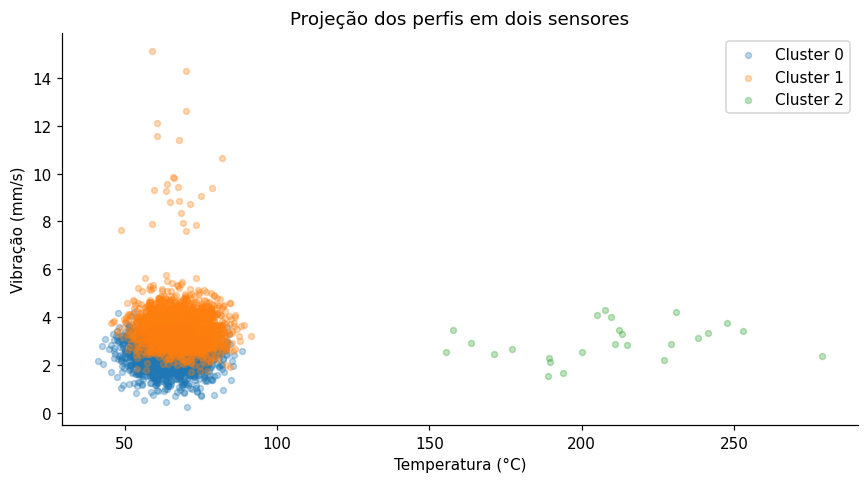

In [54]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

preparacao_clusters = Pipeline([('imputacao', SimpleImputer(strategy='median')), ('escala', StandardScaler())])
Z = preparacao_clusters.fit_transform(manutencao[sensores])
resultados_k = []
modelos_k = {}
for k in range(2, 6):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    modelos_k[k] = km
    resultados_k.append({'k': k, 'inercia': km.inertia_,
                         'silhueta': silhouette_score(Z, km.labels_, sample_size=min(1500, len(Z)), random_state=42)})
tabela_k = pd.DataFrame(resultados_k)
display(tabela_k)
k_escolhido = int(tabela_k.loc[tabela_k['silhueta'].idxmax(), 'k'])
perfis = manutencao.copy()
perfis['cluster'] = modelos_k[k_escolhido].labels_
resumo_clusters = perfis.groupby('cluster')[sensores].median()
resumo_clusters['registros'] = perfis.groupby('cluster').size()
resumo_clusters['taxa_falha'] = perfis.groupby('cluster')['falha'].mean()
print('k escolhido por silhueta:', k_escolhido)
display(resumo_clusters.round(3))
fig, ax = plt.subplots(figsize=(8, 4.5))
for cluster, grupo in perfis.groupby('cluster'):
    ax.scatter(grupo['temperatura_c'], grupo['vibracao_mm_s'], alpha=.3, s=15, label=f'Cluster {cluster}')
ax.set(xlabel='Temperatura (°C)', ylabel='Vibração (mm/s)', title='Projeção dos perfis em dois sensores')
ax.legend()
plt.tight_layout()
plt.show()

**Leitura dos perfis desta execução:** a maior silhueta foi aproximadamente **0,2204**, com **3 grupos**, indicando separação limitada. O grupo 0 reuniu 2.509 registros, mediana de 3.188,5 horas e taxa de falhas de cerca de 4,5%; o grupo 1 reuniu 2.466 registros, mediana de 8.974 horas, vibração mais elevada e cerca de 32,0% de falhas. O grupo 2 teve somente 25 registros e temperatura mediana de **209,61 °C**. Esse último grupo pode refletir valores extremos ou condições incomuns: requer conferir o sensor e o processo. Não deve ser automaticamente interpretado como um regime normal. Os números dos grupos podem mudar em outra execução ou versão.

**Aplicação:** os perfis podem orientar acompanhamento por condição operacional e priorizar investigação.
Compare tamanho, medianas e taxa de falhas antes de nomear os grupos. K-Means é sensível à escala e a extremos;
um grupo pequeno de valores extremos pode ter boa silhueta sem representar um regime útil de operação.
O desenho mostra só dois dos cinco atributos e não resume toda a geometria do agrupamento.

### 9.5. Etapa 5: PySpark e tomada de decisão · páginas 77 e 78

Esta seção é **opcional**: exige PySpark e Java compatível. A célula informa a indisponibilidade quando
o pacote não existe; nesse caso, nenhuma execução Spark é alegada. A instalação deve ser feita no ambiente
em que você pretende executá-la.

Pandas opera normalmente na memória de um processo. Spark divide tarefas em partições e usa avaliação
preguiçosa: transformações são executadas quando uma ação pede o resultado. Em uma base de 5 mil linhas,
o custo de iniciar Spark pode superar o benefício. O modo `local[2]` abaixo demonstra a API no computador;
não constitui uma medição em um cluster distribuído.

O código lê o CSV original, seleciona atributos, filtra falhas e agrupa por máquina. Uma ampliação artificial
opcional multiplica linhas para praticar processamento; não cria observações industriais independentes.

In [55]:
import importlib.util
if importlib.util.find_spec('pyspark') is None:
    print('Etapa Spark não executada: PySpark não está instalado. O código permanece disponível abaixo.')
else:
    from pyspark.sql import SparkSession, functions as F
    caminho_spark = next(p for p in [Path('dados/manutencao.csv'), Path('manutencao.csv')] if p.exists())
    spark = SparkSession.builder.master('local[2]').appName('Aula02-SM-Industry').getOrCreate()
    try:
        sdf = spark.read.option('header', True).option('inferSchema', True).csv(str(caminho_spark.resolve()))
        sdf = sdf.dropDuplicates()
        sdf.printSchema()
        sdf.select('maquina_id', 'temperatura_c', 'vibracao_mm_s', 'falha').filter(F.col('falha') == 1).show(5)
        resumo_spark = sdf.groupBy('maquina_id').agg(F.count('*').alias('registros'),
            F.sum('falha').alias('falhas'), F.avg('falha').alias('taxa_falha'))
        resumo_spark.orderBy('maquina_id').show()
        assert sdf.count() == len(manutencao)
        # Aumente para 100, por exemplo, se quiser praticar com repetição artificial.
        FATOR_AMPLIACAO = 1
        ampliada = sdf.crossJoin(spark.range(FATOR_AMPLIACAO).withColumnRenamed('id', 'replica_didatica'))
        print('Registros da demonstração ampliada:', ampliada.count())
    finally:
        spark.stop()

Etapa Spark não executada: PySpark não está instalado. O código permanece disponível abaixo.


## 10. Recomendações fundamentadas e limites · páginas 78 e 79

As frases abaixo são calculadas a partir desta execução. Os resultados sugerem prioridades de investigação;
não justificam automatizar desligamentos ou substituir inspeções sem validação com a equipe técnica.

In [56]:
maior_taxa = taxas_maquina['taxa'].idxmax()
maior_cluster = resumo_clusters['taxa_falha'].idxmax()
resultado_final = metricas[0]
print(f"1. Investigar {maior_taxa}: maior taxa descritiva de falhas ({taxas_maquina.loc[maior_taxa, 'taxa']:.1%}).")
print(f"2. Modelo escolhido na validação: {nome_escolhido}; recall no teste = {resultado_final['recall']:.3f}, F1 = {resultado_final['F1']:.3f}.")
print(f"3. Examinar o perfil {maior_cluster}: taxa de falhas de {resumo_clusters.loc[maior_cluster, 'taxa_falha']:.1%}.")
print('4. Revisar ausências, sensores e valores extremos com a manutenção antes de descartá-los.')
print('5. Definir antecedência desejada, custos dos erros e protocolo de validação prospectiva antes do uso operacional.')
print('6. Usar Spark quando volume, infraestrutura e testes de desempenho sustentarem a decisão.')

1. Investigar M04: maior taxa descritiva de falhas (18.9%).
2. Modelo escolhido na validação: Random Forest; recall no teste = 0.644, F1 = 0.513.
3. Examinar o perfil 1: taxa de falhas de 32.0%.
4. Revisar ausências, sensores e valores extremos com a manutenção antes de descartá-los.
5. Definir antecedência desejada, custos dos erros e protocolo de validação prospectiva antes do uso operacional.
6. Usar Spark quando volume, infraestrutura e testes de desempenho sustentarem a decisão.


### O que ainda precisa de validação no projeto

- Os registros atuais permitem classificar condições medidas; prever uma falha futura exige criar um alvo com horizonte definido.
- O teste temporal é uma única janela. É necessário verificar estabilidade em outros períodos e equipamentos.
- A imputação por mediana é uma escolha inicial. Investigue se ausências se concentram em máquinas ou eventos de falha.
- Taxas por máquina não isolam tempo de exposição, regime de produção ou diferenças de manutenção.
- Outliers permanecem na análise. Confirme unidade, sensor e evento antes de alterar registros.
- A comparação escolhe por F1 na validação. Custos operacionais podem exigir outro critério e calibração de probabilidades.

## 11. Revisão e desafios autorais

**1. Por que dividir defeitos pela produção?** Para comparar qualidade proporcionalmente ao volume.
Somente contar defeitos pode penalizar o turno que produz mais.

**2. `mean()` e `sum()` respondem à mesma pergunta?** Não. A média descreve o valor por registro;
a soma descreve o total do período. Ambas dependem da unidade e da granularidade da base.

**3. Temperatura e defeitos correlacionados demonstram causa?** Não. Produto, volume e outras condições
podem afetar ambos. Cinco observações não sustentam uma conclusão operacional geral.

**4. Melhor produção significa melhor eficiência?** Neste exercício D produz mais, mas E produz mais peças por kWh.

**5. Por que o imputador fica dentro do pipeline?** Para aprender as medianas só no treino de cada divisão,
sem usar informações da validação ou do teste.

**6. Por que a acurácia pode enganar na manutenção?** Uma base com poucas falhas permite muitos acertos
prevendo sempre ausência de falha. Por isso comparamos com a referência e examinamos recall e F1.

**Desafios:** altere o limite de temperatura de 75 para 80; compare a média simples das taxas com a taxa
ponderada por produção; compare viagens por dia observado em vez de totais mensais; discuta o efeito de
inflação e sazonalidade em vendas. No projeto, proponha uma validação por máquina sem executar ajustes pelo teste atual.

## 12. Conclusão da atividade

Nesta aula, construí tabelas, selecionei registros, calculei estatísticas, criei indicadores e comparei grupos.
Resolvi os exercícios de máquinas, viagens e vendas usando as bases correspondentes e distingui quantidade,
taxa e eficiência. No projeto de manutenção, apliquei exploração, preparação, classificação e agrupamento;
a seção de Spark permite continuar o estudo quando o ambiente estiver disponível.

O aprendizado central é conectar cada comando a uma pergunta e interpretar os resultados no contexto
industrial, considerando qualidade dos dados e limites das evidências.

## Referências, cobertura e decisões de implementação

**Fonte principal:** *Aula 02 - Data Science e Big Data na Indústria*, Prof. Me. Daniel Vieira,
PDF local de 81 páginas. **Modelo de apresentação:** `Aula03_Todos_os_Exemplos_Completo.ipynb`,
incluindo a capa e o logotipo incorporado, com a identificação mantida.

| Base original do PDF | Arquivo nesta entrega |
|---|---|
| [Produção por turno, página 35](https://drive.google.com/file/d/1-Nr9zufNOZSjlvkhN0H78QkUsQXxG0TB/view) | `dados/producao.csv` |
| [Viagens, página 52](https://drive.google.com/file/d/1qW-44xXKdYB2WmbKNyd17O5t_xuE70ZX/view) | `dados/base_p52.csv` |
| [Vendas, página 54](https://drive.google.com/file/d/1K1ekAHpbd6MXyxODX0CnQkk3061qYEp1/view) | `dados/base_p54.csv` |
| [Manutenção, página 61](https://drive.google.com/file/d/1yQ7P-mbRK3Gsh12ey6ahxk8szc6pOie1/view) | `dados/manutencao.csv` |

**Cobertura:** páginas 2 a 18 contextualizadas; páginas 19 a 34 reproduzidas com complementos de inspeção
e gráfico; páginas 35 a 48 consolidadas com os cálculos e os dois gráficos; páginas 49 a 55 resolvidas;
página 56 orienta entrega pelo professor; páginas 57 a 79 implementadas como roteiro autoral do projeto;
página 80 contém avaliação. Capa e encerramento (1 e 81) não trazem código.

**Correções documentadas:** `head()` exibe cinco linhas por padrão (o comentário do slide fala em quatro);
`resumo` foi definido antes dos gráficos; a questão da página 51 usa a base que contém defeitos;
as imagens trocadas de viagens/vendas não alteram os arquivos corretos dos links.

**Complementos autorais:** ferramentas adicionais de Pandas, verificações, gráficos dos exercícios,
respostas interpretadas e implementação das cinco etapas do projeto. As métricas são calculadas a partir
dos dados, sem forçar resultados dos slides. PySpark permanece opcional e sua execução é informada na saída.